# Calculative Foundation – Linear Algebra Project


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("student_scores.csv")
df

,Student,Maths,Physics,Chemistry,English,Computer
0,Aarav,85,78,82,74,90
1,Diya,92,88,85,80,95
2,Krish,67,72,65,70,68
3,Meera,78,81,79,85,82
4,Rohan,55,60,58,62,50
5,Sneha,88,90,92,78,87
6,Karan,72,68,70,75,74
7,Priya,95,93,90,88,97
8,Jay,60,58,62,66,59
9,Nisha,81,76,84,79,80


In [2]:
names = df["Student"].values
subjects = ["Maths", "Physics", "Chemistry", "English", "Computer"]
A = df[subjects].values          # matrix: students x subjects
print("Shape of matrix A:", A.shape)

Shape of matrix A: (15, 5)


# Part A: Vector & Matrix Fundamentals

### 1: Represent each student's scores as a vector

In [20]:
v1 = A[0]     
v2 = A[1]     
print("Vector of", names[0], ":", v1)
print("Vector of", names[1], ":", v2)

Vector of Aarav : [85 78 82 74 90]
Vector of Diya : [92 88 85 80 95]


### 2(a): Norm-1 and Norm-2

In [21]:
norm1_v1 = np.sum(np.abs(v1))
norm2_v1 = np.sqrt(np.sum(v1 ** 2))
print("Norm-1 of", names[0], "=", norm1_v1)
print("Norm-2 of", names[0], "=", norm2_v1)


print("Check Norm-1:", np.linalg.norm(v1, 1))
print("Check Norm-2:", np.linalg.norm(v1, 2))

Norm-1 of Aarav = 409
Norm-2 of Aarav = 183.3275756671647
Check Norm-1: 409.0
Check Norm-2: 183.3275756671647


### 2(b): Dot product and angle between two students

In [5]:
dot = np.dot(v1, v2)
angle_rad = np.arccos(dot / (np.linalg.norm(v1) * np.linalg.norm(v2)))
angle_deg = np.degrees(angle_rad)
print("Dot product of", names[0], "and", names[1], "=", dot)
print("Angle between them (degrees) =", round(angle_deg, 4))

Dot product of Aarav and Diya = 36124
Angle between them (degrees) = 1.6133


### 2(c): Cross product (3D: Maths, Physics, Chemistry)

In [6]:
a3 = v1[:3]
b3 = v2[:3]
cross = np.cross(a3, b3)
print("3D vector of", names[0], ":", a3)
print("3D vector of", names[1], ":", b3)
print("Cross product =", cross)

3D vector of Aarav : [85 78 82]
3D vector of Diya : [92 88 85]
Cross product = [-586  319  304]


### 3: Projection of one vector onto another

In [22]:
proj = (np.dot(v1, v2) / np.dot(v2, v2)) * v2
print("Projection of", names[0], "onto", names[1], "=", np.round(proj, 3))

Projection of Aarav onto Diya = [85.527 81.808 79.02  74.371 88.316]


# Part B: Matrix Operations

### 4: Matrix of students x subjects

In [8]:
print("Matrix A (students x subjects):")
print(A)

Matrix A (students x subjects):
[[85 78 82 74 90]
 [92 88 85 80 95]
 [67 72 65 70 68]
 [78 81 79 85 82]
 [55 60 58 62 50]
 [88 90 92 78 87]
 [72 68 70 75 74]
 [95 93 90 88 97]
 [60 58 62 66 59]
 [81 76 84 79 80]
 [70 74 68 72 77]
 [89 85 87 91 86]
 [64 66 61 68 63]
 [76 79 81 83 78]
 [58 55 60 64 57]]


**Matrix addition** (add 5 grace marks to everyone)

In [9]:
B = np.ones(A.shape, dtype=int) * 5
C = A + B
print("A + B, first 3 rows:")
print(C[:3])

A + B, first 3 rows:
[[ 90  83  87  79  95]
 [ 97  93  90  85 100]
 [ 72  77  70  75  73]]


**Matrix multiplication** (weighted score)

In [10]:
W = np.array([[0.3], [0.2], [0.2], [0.1], [0.2]])
weighted = A @ W
print("A x W, first 5 students:")
print(np.round(weighted[:5], 2))

A x W, first 5 students:
[[82.9]
 [89.2]
 [68.1]
 [80.3]
 [56.3]]


**Transpose**

In [11]:
At = A.T
print("Shape of A transpose:", At.shape)

Shape of A transpose: (5, 15)


**Determinant and Inverse** (A is 15x5, not square, so we use S = AᵀA which is 5x5)

In [12]:
S = At @ A
print("S = A^T x A (5x5):")
print(S)

det_S = np.linalg.det(S)
print("\nDeterminant of S =", det_S)

S = A^T x A (5x5):
[[87458 86618 86750 86874 88621]
 [86618 86009 85977 86221 87766]
 [86750 85977 86218 86327 87844]
 [86874 86221 86327 86969 87952]
 [88621 87766 87844 87952 89935]]

Determinant of S = 150581224139094.3


In [13]:
if det_S != 0:
    S_inv = np.linalg.inv(S)
    print("Inverse of S exists:")
    print(S_inv)
    print("\nCheck S x S_inv (should be identity):")
    print(np.round(S @ S_inv, 3))
else:
    print("Inverse does not exist (singular matrix)")

Inverse of S exists:
[[ 0.02288934 -0.00208771 -0.009      -0.00015172 -0.01157843]
 [-0.00208771  0.00597958 -0.00118145 -0.00146902 -0.00118755]
 [-0.009      -0.00118145  0.00854147 -0.00132002  0.0029695 ]
 [-0.00015172 -0.00146902 -0.00132002  0.00225756  0.00066464]
 [-0.01157843 -0.00118755  0.0029695   0.00066464  0.00902885]]

Check S x S_inv (should be identity):
[[ 1.  0. -0.  0. -0.]
 [-0.  1. -0.  0. -0.]
 [-0. -0.  1.  0.  0.]
 [-0.  0. -0.  1.  0.]
 [ 0.  0. -0.  0.  1.]]


# Part C: Linear Transformations & Geometry

### 5: Line, Plane and Hyperplane
- **Line (1D):** a*x + b*y = c in 2D (e.g. Maths vs Physics)
- **Plane (2D):** a*x + b*y + c*z = d in 3D (Maths, Physics, Chemistry)
- **Hyperplane:** w1*x1 + ... + wn*xn = b. Our dataset has 5 subjects, so each student is a point in 5D space and a hyperplane is 4-dimensional.

### 6: Dimensionality 2D → 3D → higher

In [14]:
print("2D space : line is the hyperplane (n-1 = 1 dimension)")
print("3D space : plane is the hyperplane (n-1 = 2 dimensions)")
print("5D space : hyperplane has n-1 = 4 dimensions (our dataset)")

2D space : line is the hyperplane (n-1 = 1 dimension)
3D space : plane is the hyperplane (n-1 = 2 dimensions)
5D space : hyperplane has n-1 = 4 dimensions (our dataset)


**2D plot: Line** (Maths + Physics = 150)

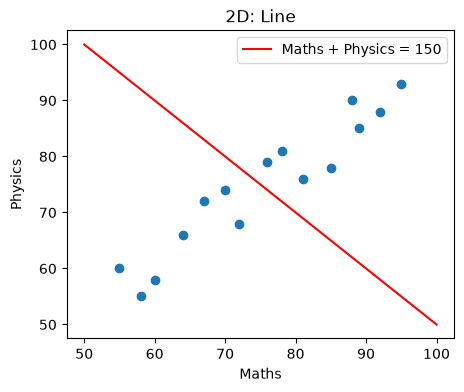

In [15]:
plt.figure(figsize=(5, 4))
plt.scatter(df["Maths"], df["Physics"])
x = np.linspace(50, 100, 50)
y = 150 - x
plt.plot(x, y, color="red", label="Maths + Physics = 150")
plt.xlabel("Maths")
plt.ylabel("Physics")
plt.title("2D: Line")
plt.legend()
plt.show()

**3D plot: Plane** (Maths + Physics + Chemistry = 240)

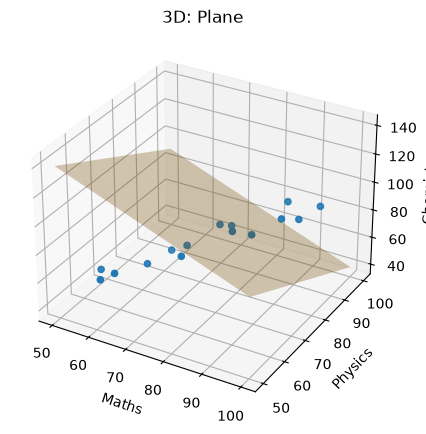

In [16]:
fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(df["Maths"], df["Physics"], df["Chemistry"])
xx, yy = np.meshgrid(np.linspace(50, 100, 10), np.linspace(50, 100, 10))
zz = 240 - xx - yy
ax.plot_surface(xx, yy, zz, alpha=0.3, color="orange")
ax.set_xlabel("Maths")
ax.set_ylabel("Physics")
ax.set_zlabel("Chemistry")
ax.set_title("3D: Plane")
plt.show()

# Part D: Eigenvalues & Decomposition

### 7: Eigenvalues and eigenvectors of the covariance matrix

In [17]:
mean = A.mean(axis=0)
A_centered = A - mean
cov = (A_centered.T @ A_centered) / (A.shape[0] - 1)
print("Covariance matrix:")
print(np.round(cov, 2))

print("\nCheck with np.cov (should match):")
print(np.round(np.cov(A.T), 2))

Covariance matrix:
[[166.52 144.19 148.24  97.9  179.64]
 [144.19 138.12 130.49  89.1  156.67]
 [148.24 130.49 142.35  91.26 156.8 ]
 [ 97.9   89.1   91.26  77.67 104.64]
 [179.64 156.67 156.8  104.64 202.74]]

Check with np.cov (should match):
[[166.52 144.19 148.24  97.9  179.64]
 [144.19 138.12 130.49  89.1  156.67]
 [148.24 130.49 142.35  91.26 156.8 ]
 [ 97.9   89.1   91.26  77.67 104.64]
 [179.64 156.67 156.8  104.64 202.74]]


In [18]:
eig_vals, eig_vecs = np.linalg.eig(cov)

# sort from big to small
idx = np.argsort(eig_vals)[::-1]
eig_vals = eig_vals[idx]
eig_vecs = eig_vecs[:, idx]

print("Eigenvalues:")
print(np.round(eig_vals, 3))
print("\nEigenvectors (each column is one eigenvector):")
print(np.round(eig_vecs, 3))

Eigenvalues:
[685.284  19.406  10.941   9.616   2.163]

Eigenvectors (each column is one eigenvector):
[[-0.489  0.185 -0.089  0.2    0.824]
 [-0.436 -0.049  0.01  -0.898 -0.028]
 [-0.443 -0.204 -0.764  0.229 -0.355]
 [-0.301 -0.818  0.449  0.196  0.006]
 [-0.533  0.502  0.455  0.25  -0.441]]


In [19]:
total = np.sum(eig_vals)
print("Variance explained by each eigenvalue (%):")
print(np.round(eig_vals / total * 100, 2))

Variance explained by each eigenvalue (%):
[94.21  2.67  1.5   1.32  0.3 ]


### Interpretation
- The biggest eigenvalue shows the direction of maximum variance, which is the students' **overall performance**.
- Small eigenvalues show directions with very little variation, so they can be dropped in PCA (dimensionality reduction).